In [1]:
import re
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.io as sio
from tqdm.auto import tqdm

In [2]:
DATA_ROOT = Path.cwd()
OUTPUT_ROOT = DATA_ROOT / "parquet"
OUTPUT_ROOT.mkdir(exist_ok=True)
TEST_DIR = DATA_ROOT / "test"

In [3]:
OPTUNA_N_TRIALS = 15

In [4]:
FILENAME_RE = re.compile(
    r"^(?P<speed_code>N\d{2})_(?P<load_code>M\d{2})_(?P<force_code>F\d{2})_"
    r"(?P<bearing_code>[A-Z]{1,2}\d{2,3})_(?P<run>\d+)$"
)

SPEED_RPM = {"N09": 900, "N15": 1500}
LOAD_TORQUE_NM = {"M07": 0.7, "M01": 0.1}
RADIAL_FORCE_N = {"F10": 1000, "F04": 400}

In [5]:
# TARGET_MAPPING = {
#     **{code: "healthy" for code in ["K001", "K002", "K003", "K004", "K005", "K006"]},
#     **{
#         code: "artificial_damage_outer_ring"
#         for code in ["KA01", "KA03", "KA05", "KA06", "KA07", "KA08", "KA09"]
#     },
#     **{
#         code: "artificial_damage_inner_ring"
#         for code in ["KI01", "KI03", "KI05", "KI07", "KI08"]
#     },
#     **{
#         code: "real_damage_outer_ring"
#         for code in ["KA04", "KA15", "KA16", "KA22", "KA30"]
#     },
#     **{
#         code: "real_damage_inner_ring"
#         for code in ["KI04", "KI14", "KI16", "KI17", "KI18", "KI21"]
#     },
#     **{code: "real_damage_both_rings" for code in ["KB23", "KB24", "KB27"]},
# }

In [6]:
TARGET_MAPPING = {
    **{code: "healthy" for code in ["K001", "K002", "K003", "K004", "K005", "K006"]},
    **{
        code: "artificial_damage"
        for code in ["KA01", "KA03", "KA05", "KA06", "KA07", "KA08", "KA09", "KI01", "KI03", "KI05", "KI07", "KI08"]
    },
    **{
        code: "real_damage"
        for code in ["KA04", "KA15", "KA16", "KA22", "KA30", "KI04", "KI14", "KI16", "KI17", "KI18", "KI21", "KB23", "KB24", "KB27"]
    }
}

In [7]:
def bearing_condition(bearing_code: str) -> str:
    return TARGET_MAPPING[bearing_code]


def parse_filename(stem: str) -> dict:
    m = FILENAME_RE.match(stem)
    if not m:
        raise ValueError(f"Filename does not match the expected pattern: {stem!r}")
    g = m.groupdict()
    for code, table, label in (
        (g["speed_code"], SPEED_RPM, "speed_code"),
        (g["load_code"], LOAD_TORQUE_NM, "load_code"),
        (g["force_code"], RADIAL_FORCE_N, "force_code"),
    ):
        if code not in table:
            raise ValueError(f"Unknown {label} {code!r} in {stem!r}")
    return {
        "file_stem": stem,
        "speed_rpm": SPEED_RPM[g["speed_code"]],
        "load_torque_nm": LOAD_TORQUE_NM[g["load_code"]],
        "radial_force_n": RADIAL_FORCE_N[g["force_code"]],
        "bearing_code": g["bearing_code"],
        "bearing_condition": bearing_condition(g["bearing_code"]),
        "run": int(g["run"]),
    }

In [8]:
def _slug(raster: str) -> str:
    return re.sub(r"[^a-z0-9]+", "_", raster.lower()).strip("_")


def load_mat_file(path: Path) -> tuple[dict[str, pd.DataFrame], dict]:
    """Load one Paderborn .mat measurement into {raster_name: DataFrame} + metadata."""
    raw = sio.loadmat(path, struct_as_record=False, squeeze_me=True)
    key = next(k for k in raw if not k.startswith("__"))
    top = raw[key]

    time_by_raster = {
        x.Raster: np.asarray(x.Data, dtype=float) for x in np.atleast_1d(top.X)
    }

    channels_by_raster: dict[str, dict[str, np.ndarray]] = {}
    for ch in np.atleast_1d(top.Y):
        channels_by_raster.setdefault(ch.Raster, {})[ch.Name] = np.asarray(
            ch.Data, dtype=float
        )

    frames = {}
    for raster, channels in channels_by_raster.items():
        df = pd.DataFrame(channels)
        time = time_by_raster.get(raster)
        if time is not None and len(time) == len(df):
            df.insert(0, "time_s", time)
        frames[raster] = df

    metadata = {
        "measurement_id": int(top.Info.MeasurementID),
        "recording_datetime": datetime.strptime(
            str(top.Description.General.DateTime), "%d.%m.%Y %H:%M:%S"
        ),
        "measurement_length_s": float(top.Description.Measurement.Length),
    }
    return frames, metadata

In [9]:
_sample_path = DATA_ROOT / "K001" / "N09_M07_F10_K001_1.mat"
_frames, _meta = load_mat_file(_sample_path)

print(_meta)
for raster, df in _frames.items():
    print(raster, df.shape, list(df.columns))
_frames["HostService"].head()

{'measurement_id': 22, 'recording_datetime': datetime.datetime(2015, 9, 17, 19, 51, 22), 'measurement_length_s': 4.0}
Mech_4kHz (16008, 4) ['time_s', 'force', 'speed', 'torque']
HostService (256823, 4) ['time_s', 'phase_current_1', 'phase_current_2', 'vibration_1']
Temp_1Hz (5, 2) ['time_s', 'temp_2_bearing_module']


,time_s,phase_current_1,phase_current_2,vibration_1
0,-0.000003,-0.872686,-1.146133,0.064087
1,0.000012,-0.945697,-1.245317,-0.122070
2,0.000028,-1.037994,-1.368609,0.112915
3,0.000043,-0.922279,-1.321083,0.384521
4,0.000059,-0.823094,-1.188148,0.079346


In [10]:
def convert_and_save(mat_path: Path, output_root: Path) -> dict:
    """Convert one .mat file to per-raster Parquet files and return a catalog row."""
    mat_path = Path(mat_path)
    meta = parse_filename(mat_path.stem)
    frames, mat_meta = load_mat_file(mat_path)

    bearing_dir = output_root / meta["bearing_code"]
    bearing_dir.mkdir(parents=True, exist_ok=True)

    row = {**meta, **mat_meta, "source_file": str(mat_path)}
    for raster, df in frames.items():
        slug = _slug(raster)
        out_path = bearing_dir / f"{mat_path.stem}__{slug}.parquet"
        df.to_parquet(out_path, index=False)
        row[f"n_samples_{slug}"] = len(df)
        row[f"path_{slug}"] = str(out_path.relative_to(output_root))
    return row


def discover_mat_files(data_root: Path) -> list[Path]:
    return sorted(data_root.glob("K*/*.mat"))


def build_catalog(mat_files: list[Path], output_root: Path) -> pd.DataFrame:
    rows, errors = [], []
    for f in tqdm(mat_files):
        try:
            rows.append(convert_and_save(f, output_root))
        except Exception as exc:
            errors.append((str(f), repr(exc)))
    if errors:
        print(f"{len(errors)} file(s) failed:")
        for f, e in errors:
            print(" ", f, "->", e)
    return pd.DataFrame(rows)

Читаем директории и конвертируем .mat в .parquet


In [11]:
all_mat_files = discover_mat_files(DATA_ROOT)

In [12]:
catalog = build_catalog(all_mat_files, OUTPUT_ROOT)
catalog.to_parquet(OUTPUT_ROOT / "catalog.parquet", index=False)
catalog.to_csv(OUTPUT_ROOT / "catalog.csv", index=False)

  0%|          | 0/1920 [00:00<?, ?it/s]

In [13]:
catalog.head()

,file_stem,speed_rpm,load_torque_nm,radial_force_n,bearing_code,bearing_condition,run,measurement_id,recording_datetime,measurement_length_s,source_file,n_samples_mech_4khz,path_mech_4khz,n_samples_hostservice,path_hostservice,n_samples_temp_1hz,path_temp_1hz
0,N09_M07_F10_K001_1,900,0.7,1000,K001,healthy,1,22,2015-09-17 19:51:22,4.0,D:\Almaz\ML_Ваттметрирование\Datasets\K001\N09...,16008,K001\N09_M07_F10_K001_1__mech_4khz.parquet,256823,K001\N09_M07_F10_K001_1__hostservice.parquet,5,K001\N09_M07_F10_K001_1__temp_1hz.parquet
1,N09_M07_F10_K001_10,900,0.7,1000,K001,healthy,10,31,2015-09-17 20:00:03,4.0,D:\Almaz\ML_Ваттметрирование\Datasets\K001\N09...,16007,K001\N09_M07_F10_K001_10__mech_4khz.parquet,256608,K001\N09_M07_F10_K001_10__hostservice.parquet,5,K001\N09_M07_F10_K001_10__temp_1hz.parquet
2,N09_M07_F10_K001_11,900,0.7,1000,K001,healthy,11,32,2015-09-17 20:00:37,4.0,D:\Almaz\ML_Ваттметрирование\Datasets\K001\N09...,16007,K001\N09_M07_F10_K001_11__mech_4khz.parquet,256096,K001\N09_M07_F10_K001_11__hostservice.parquet,5,K001\N09_M07_F10_K001_11__temp_1hz.parquet
3,N09_M07_F10_K001_12,900,0.7,1000,K001,healthy,12,33,2015-09-17 20:01:10,4.0,D:\Almaz\ML_Ваттметрирование\Datasets\K001\N09...,16001,K001\N09_M07_F10_K001_12__mech_4khz.parquet,256000,K001\N09_M07_F10_K001_12__hostservice.parquet,5,K001\N09_M07_F10_K001_12__temp_1hz.parquet
4,N09_M07_F10_K001_13,900,0.7,1000,K001,healthy,13,34,2015-09-17 20:01:41,4.0,D:\Almaz\ML_Ваттметрирование\Datasets\K001\N09...,16001,K001\N09_M07_F10_K001_13__mech_4khz.parquet,256000,K001\N09_M07_F10_K001_13__hostservice.parquet,5,K001\N09_M07_F10_K001_13__temp_1hz.parquet


In [14]:
BALL_PARAMS = dict(d_ball=6.75, d_pitch=28.55, n_balls=8, phi=0, pole_pairs=4)
FS = 64000.0
HARMONICS = [1, 2, 3]
# TARGET_NAME_TO_CODE = {
#     "healthy": 0,
#     "artificial_damage_outer_ring": 1,
#     "real_damage_outer_ring": 2,
#     "real_damage_both_rings": 3,
#     "artificial_damage_inner_ring": 4,
#     "real_damage_inner_ring": 5,
# }
TARGET_NAME_TO_CODE = {
    "healthy": 0,
    "artificial_damage": 1,
    "real_damage": 2,
}
# N_CLASSES = 6
N_CLASSES = 3

In [15]:
def bearing_freqs():
    r = BALL_PARAMS["d_ball"] / BALL_PARAMS["d_pitch"] * np.cos(BALL_PARAMS["phi"])
    n = BALL_PARAMS["n_balls"]
    return {
        "BPFO": n / 2 * (1 - r),
        "BPFI": n / 2 * (1 + r),
        "BSF": BALL_PARAMS["d_pitch"] / (2 * BALL_PARAMS["d_ball"]) * (1 - r**2),
        "FTF": 0.5 * (1 - r),
    }

In [16]:
import scipy
import polars as pl

In [17]:
def fourier_transform_vibration(frame: pd.Series, fs: float):
    """Преобразование Фурье для сигналов вибрации"""
    x = frame.to_numpy()
    ny = fs / 2
    band = [2000, ny * 0.95]

    sos = scipy.signal.butter(4, band, btype="bandpass", fs=fs, output="sos")
    x_filt = scipy.signal.sosfiltfilt(sos, (x - x.mean()))
    env = np.abs(scipy.signal.hilbert(x_filt))
    env -= env.mean()

    window = scipy.signal.windows.hann(len(env))
    fft_values = scipy.fft.rfft(env * window)
    freqs = scipy.fft.rfftfreq(len(env), 1 / fs)
    amps = np.abs(fft_values) * 2 / np.sum(window)
    return dict(frequences=freqs, amplitudes=amps)

In [18]:
def fourier_transform_current(frame: pd.Series, fs: float):
    """Преобразование Фурье для сигналов тока"""
    x = frame.to_numpy()

    window = scipy.signal.windows.hann(len(x))
    fft_values = scipy.fft.rfft((x - x.mean()) * window)
    freqs = scipy.fft.rfftfreq(len(x), 1 / fs)
    amps = np.abs(fft_values) * 2 / np.sum(window)
    return dict(frequences=freqs, amplitudes=amps)

In [19]:
def peak_amplitude(freqs, amps, f0, tol):
    if f0 <= 0 or f0 >= freqs[-1]:
        return 0.0
    mask = (freqs >= f0 - tol) & (freqs <= f0 + tol)
    return amps[mask].max()

In [20]:
def prepare_time_features(frame: pd.DataFrame, agg_cols: list[str]):
    N = frame.shape[0] // 4
    features = {}
    time_df = pd.DataFrame(index=frame.index)
    for col in agg_cols:
        time_df[f"{col}_kurtosis"] = frame[f"{col}"].rolling(N).kurt()
        time_df[f"{col}_mean"] = frame[f"{col}"].rolling(N).mean()
        time_df[f"{col}_min"] = frame[f"{col}"].rolling(N).min()
        time_df[f"{col}_max"] = frame[f"{col}"].rolling(N).max()
        time_df[f"{col}_std"] = frame[f"{col}"].rolling(N).std()
        time_df[f"{col}_skew"] = frame[f"{col}"].rolling(N).skew()

    time_df = time_df.dropna()
    values_per_second = time_df.iloc[::N].iloc[1:]
    for col in time_df.columns:
        for t, val in enumerate(values_per_second[col]):
            features[f"{col}__t{(t+1)}"] = val

    return features

Итеративно обрабатываем метадатасет и применяем преобразования...


In [21]:
import pywt


def prepare_wpd_features(
    df: pd.DataFrame, prefix: str, level: int = 3, wavelet: str = "db4"
) -> dict:
    x = df[prefix].to_numpy()
    """Нормированные энергии вейвлет-пакетного разложения"""

    wp = pywt.WaveletPacket(data=x, wavelet=wavelet, mode="symmetric", maxlevel=level)
    nodes = [n.path for n in wp.get_level(level, "natural")]
    e = np.array([np.sum(wp[p].data ** 2) for p in nodes], dtype=np.float64)
    e = e / (e.sum() + 1e-20)
    return {f"{prefix}_wpd{i}": float(v) for i, v in enumerate(e)}

In [22]:
def welch_psd(x: np.ndarray, fs: float, nperseg: int = 4096):
    f, p = scipy.signal.welch(x, fs=fs, nperseg=min(nperseg, len(x)), scaling="density")
    return f, p + 1e-20


def prepare_spectral_features(df: pd.DataFrame, fs: float, prefix: str, n_bands: int = 10) -> dict:
    """Логарифмические энергии в полосах"""
    x = df[prefix].to_numpy()
    f, p = welch_psd(x, fs)
    pn = p / p.sum()
    out = {
        f"{prefix}_sp_centroid": float((f * pn).sum()),
        f"{prefix}_sp_spread": float(np.sqrt((((f - (f * pn).sum()) ** 2) * pn).sum())),
        f"{prefix}_sp_entropy": float(-(pn * np.log(pn)).sum() / np.log(len(pn))),
    }

    # лог. сетка от 10 Гц до частоты Найквиста
    edges = np.logspace(np.log10(10.0), np.log10(fs / 2), n_bands + 1)
    for i in range(n_bands):
        m = (f >= edges[i]) & (f < edges[i + 1])
        out[f"{prefix}_band{i}"] = (
            float(np.log10(p[m].sum() + 1e-20)) if m.any() else -20.0
        )
    return out

In [23]:
def prepare_feature_spectrum(df: pd.DataFrame, prefix: str, rpm: int):
    """
    Готовим спектральные признаки по каждой заданной в словаре частоте.
    - prefix - имя колонки, ток или вибрация
    - bearing_features - словарь с нужными частотами, на которых ищем аномалии, причем базовая частота идет как скорость вращения вала / 60
    - harmonics - нужная нам гармоника
    - rpm - частота вращения
    - f_e - частота питания
    - fr - частота вращения / 60
    - tol - допущение, в пределах которого искомая частота
    - f0 - коэффициент нужной частоты (bpfi, bpfo, ftf, bsf)
    """
    fr = rpm / 60
    features = {}
    bearing_features = bearing_freqs().items()
    if prefix.startswith("vibration"):
        # вибрация
        fourier_signal = fourier_transform_vibration(df[prefix], FS)
        freqs = fourier_signal["frequences"]
        amps = fourier_signal["amplitudes"]

        floor = np.median(amps[(freqs > 5) & (freqs < 1000)]) + 1e-12
        tol = max(2.0, 3 * (freqs[1] - freqs[0]))

        # гармоники
        for name, f0 in bearing_features:
            for h in HARMONICS:
                features[f"{prefix}_{name}_h{h}"] = (
                    peak_amplitude(freqs, amps, h * f0 * fr, tol) / floor
                )

        # боковые полосы
        for s in (-1, 1):
            tag = "p" if s > 0 else "m"
            features[f"{prefix}_BPFI_{tag}"] = (
                peak_amplitude(freqs, amps, bearing_freqs()["BPFI"] * fr + s * fr, tol)
                / floor
            )

        # частота вращения
        features[f"{prefix}_env_fr"] = peak_amplitude(freqs, amps, fr, tol)
        # features[f"{prefix}_env_rms"] = float(np.sqrt(np.mean(env**2)))
    else:
        # токи
        fourier_signal = fourier_transform_current(df[prefix], FS)
        freqs = fourier_signal["frequences"]
        amps = fourier_signal["amplitudes"]
        f_e = fr * BALL_PARAMS["pole_pairs"]
        tol = max(2.0, 3 * (freqs[1] - freqs[0]))

        # частота несущая
        f_e_amp = peak_amplitude(freqs, amps, f_e, tol) + 1e-12
        features[f"{prefix}_fe_amp"] = f_e_amp
        for name, f0 in bearing_features:
            for s in (-1, 1):
                tag = "p" if s == 1 else "m"
                features[f"{prefix}_{name}_{tag}"] = (
                    peak_amplitude(freqs, amps, f_e + s * f0 * fr, tol) / f_e_amp
                )

        # гармоники питания
        for k in (2, 3, 5):
            features[f"{prefix}_fe_h{k}"] = peak_amplitude(freqs, amps, k * f_e, tol)

    return features

In [24]:
def prepare_hostservice(path: str, rpm: int, agg_cols: list[str]):
    features = {}
    frame = pd.read_parquet(path)
    for i in [1, 2]:
        spectrum = prepare_feature_spectrum(frame, f"phase_current_{i}", rpm)
        features.update(spectrum)
        features.update(prepare_wpd_features(frame, f"phase_current_{i}"))
        features.update(prepare_spectral_features(frame, FS, f"phase_current_{i}"))

    features.update(prepare_feature_spectrum(frame, "vibration_1", rpm))
    features.update(prepare_spectral_features(frame, FS, "vibration_1"))
    features.update(prepare_wpd_features(frame, "vibration_1"))
    features.update(prepare_time_features(frame, agg_cols))
    return features

In [25]:
def preprocessing(df: pd.DataFrame):
    cols = [
        "speed_rpm",
        "load_torque_nm",
        "radial_force_n",
        "bearing_condition",
        "measurement_id",
        "path_hostservice",
        "bearing_code",
    ]
    result = df.copy().loc[:, cols]

    aggregate_cols = ["phase_current_1", "phase_current_2", "vibration_1"]
    feature_rows = []
    for _, row in tqdm(df.iterrows()):
        features = {}

        current_data_path = OUTPUT_ROOT / row["path_hostservice"]
        features.update(
            prepare_hostservice(current_data_path, row["speed_rpm"], aggregate_cols)
        )

        feature_rows.append(features)

    features_df = pd.DataFrame(feature_rows, index=result.index)
    result = pd.concat([result, features_df], axis=1)
    # current_columns = [col for col in result.columns if "current" in col]
    # result[current_columns] = result[current_columns].ffill()
    # result = result.sort_values(by="measurement_id")
    return result

In [26]:
preprocessed_df = preprocessing(catalog)

0it [00:00, ?it/s]

In [27]:
preprocessed_df

,speed_rpm,load_torque_nm,radial_force_n,bearing_condition,measurement_id,path_hostservice,bearing_code,phase_current_1_fe_amp,phase_current_1_BPFO_m,phase_current_1_BPFO_p,...,vibration_1_min__t3,vibration_1_max__t1,vibration_1_max__t2,vibration_1_max__t3,vibration_1_std__t1,vibration_1_std__t2,vibration_1_std__t3,vibration_1_skew__t1,vibration_1_skew__t2,vibration_1_skew__t3
0,900,0.7,1000,healthy,22,K001\N09_M07_F10_K001_1__hostservice.parquet,K001,2.193268,0.000262,0.000277,...,-4.843140,3.771973,4.690552,4.141235,0.364229,0.365423,0.367673,-0.024172,0.087590,-0.048972
1,900,0.7,1000,healthy,31,K001\N09_M07_F10_K001_10__hostservice.parquet,K001,2.052334,0.000468,0.000306,...,-3.833008,4.037476,4.000854,4.049683,0.363079,0.361361,0.363440,-0.026363,0.053745,0.006471
2,900,0.7,1000,healthy,32,K001\N09_M07_F10_K001_11__hostservice.parquet,K001,2.410373,0.000264,0.000238,...,-3.833008,4.455566,3.866577,4.104614,0.360117,0.363880,0.362216,0.071844,-0.021445,0.067747
3,900,0.7,1000,healthy,33,K001\N09_M07_F10_K001_12__hostservice.parquet,K001,2.404953,0.000346,0.000238,...,-5.166626,3.747559,4.055786,4.180908,0.360075,0.360837,0.360692,0.065863,0.043941,0.040132
4,900,0.7,1000,healthy,34,K001\N09_M07_F10_K001_13__hostservice.parquet,K001,2.407388,0.000287,0.000307,...,-3.909302,4.183960,3.311157,4.431152,0.360323,0.365994,0.359603,0.212147,0.093068,0.266342
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1915,1500,0.7,1000,real_damage,13,KI21\N15_M07_F10_KI21_5__hostservice.parquet,KI21,2.334538,0.000193,0.000189,...,-1.629639,1.477051,1.440430,1.538086,0.285370,0.286223,0.286506,-0.009478,-0.011467,-0.007427
1916,1500,0.7,1000,real_damage,14,KI21\N15_M07_F10_KI21_6__hostservice.parquet,KI21,2.388890,0.000141,0.000229,...,-1.373291,1.730347,1.544189,1.580811,0.286606,0.281261,0.281030,-0.016216,0.018106,-0.046623
1917,1500,0.7,1000,real_damage,15,KI21\N15_M07_F10_KI21_7__hostservice.parquet,KI21,2.550899,0.000233,0.000217,...,-1.544189,1.452637,1.406860,1.562500,0.281159,0.288552,0.287499,-0.007959,-0.013151,-0.004016
1918,1500,0.7,1000,real_damage,17,KI21\N15_M07_F10_KI21_8__hostservice.parquet,KI21,2.513107,0.000204,0.000165,...,-1.370239,1.516724,1.583862,1.608276,0.287711,0.285426,0.285444,0.002513,-0.043005,-0.010792


In [28]:
def prepare_target(df: pd.DataFrame):
    X = df.drop(
        [
            "measurement_id",
            "bearing_condition",
            "bearing_code",
            "path_hostservice",
            # "speed_rpm",
            # "radial_force_n",
            # "load_torque_nm",
        ],
        axis=1,
    )
    y = df["bearing_condition"].map(TARGET_NAME_TO_CODE)

    groups = df["bearing_code"]
    return X, y, groups

In [29]:
from sklearn.preprocessing import StandardScaler


def scale_features(X, scaler=None):
    X_arr = (
        X.to_numpy(dtype=np.float32)
        if hasattr(X, "to_numpy")
        else np.asarray(X, dtype=np.float32)
    )

    if scaler is None:
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X_arr)
    else:
        X_scaled = scaler.transform(X_arr)

    return X_scaled, scaler

In [30]:
def calc_class_weights(y: np.ndarray):
    class_count = torch.bincount(torch.tensor(y, dtype=torch.long))
    weights = len(y) / (len(class_count) * class_count.float())
    return weights

In [31]:
from sklearn.model_selection import StratifiedGroupKFold


def train_test_split(
    X: pd.DataFrame,
    y: np.ndarray,
    groups: pd.Series,
    n_splits=2,
    test_size=0.3,
    random_state=42,
):
    splitter = StratifiedGroupKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state
    )
    return splitter.split(X, y, groups=groups)

In [32]:
X, y, groups = prepare_target(preprocessed_df)
train_test_idx = train_test_split(X, y, groups, n_splits=OPTUNA_N_TRIALS)

In [33]:
import matplotlib.pyplot as plt


def plot_loss(train_losses: list[float], val_losses: list[float], num_epochs: int):
    epochs = range(1, num_epochs + 1)
    fig, ax = plt.subplots(figsize=(10, 6))

    ax.plot(epochs, train_losses, label="Train loss")
    ax.plot(epochs, val_losses, label="Val loss")

    ax.set_xlabel("Эпоха")
    ax.set_ylabel("Loss")
    ax.set_title("Графики лосса обучения и валидации")
    ax.legend()

    plt.tight_layout()
    plt.show()

In [34]:
import torch


def validate_model(model, val_loader, criterion):
    model.eval()
    correct = 0
    total = 0
    val_loss = 0.0

    with torch.no_grad():
        for inputs, labels in val_loader:
            outputs = model(inputs)

            loss = criterion(outputs, labels)
            val_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    print(f"Val accuracy: {accuracy}%, loss = {val_loss / len(val_loader)}")
    return val_loss

In [35]:
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=10):
    train_losses = []
    val_losses = []
    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0

        for inputs, labels in train_loader:
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        avg_loss = running_loss / len(train_loader)
        train_losses.append(avg_loss)
        print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {avg_loss:.4f}")

        val_loss = validate_model(model, val_loader, criterion)
        val_loss = val_loss / len(val_loader)
        val_losses.append(val_loss)

    plot_loss(train_losses, val_losses, num_epochs)
    return np.mean(val_losses)

In [36]:
from torch.utils.data import DataLoader, TensorDataset


def prepare_torch_dataset(X_train, X_test, y_train, y_test, normalize=False):
    scaler = StandardScaler()
    if normalize:
        X_train, scaler = scale_features(X_train)
        X_test, _ = scale_features(X_test, scaler)
    else:
        X_train = X_train.to_numpy(dtype=np.float32)
        X_test = X_test.to_numpy(dtype=np.float32)

    X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.long)

    X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
    y_test_tensor = torch.tensor(y_test.to_numpy(), dtype=torch.long)

    train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
    test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
    return train_loader, test_loader, scaler

### Модель

In [37]:
import torch
import torch.nn as nn


class DeepFeedForward(nn.Module):
    def __init__(self, layers):
        super().__init__()
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

    def predict(self, x):
        with torch.no_grad():
            return self.forward(x)

In [38]:
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, inputs, targets):
        ce = nn.functional.cross_entropy(inputs, targets, weight=self.alpha)
        pt = torch.exp(-ce)
        loss = ((1 - pt) ** self.gamma) * ce
        return loss.mean()

In [39]:
def make_objective(train_test_idx):
    train_idx, test_idx = next(train_test_idx)
    X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
    X_val, y_val = X.iloc[test_idx], y.iloc[test_idx
                                              ]
    train_loader, val_loader, scaler = prepare_torch_dataset(
        X_train, X_val, y_train, y_val, normalize=True
    )
    
    weights = calc_class_weights(np.asarray(y_train.to_numpy(), dtype=np.int64))
    # criterion = nn.CrossEntropyLoss(weight=weights)
    criterion = FocalLoss()

    activations = {"ReLU": nn.ReLU(), "Sigmoid": nn.Sigmoid(), "LeakyReLU": nn.LeakyReLU()}

    def objective(trial):
        n_layers = trial.suggest_int("n_layers", 1, 10)
        activation = trial.suggest_categorical(
            "activation", ["ReLU", "Sigmoid", "LeakyReLU"]
        )
        dropout = trial.suggest_float("dropout", 0.2, 0.8)
        layers = []
        in_features = X_train.shape[1]

        for i in range(n_layers):
            out_features = trial.suggest_int(f"n_units_l{i}", 64, 128)
            layers.append(nn.Linear(in_features, out_features))
            layers.append(activations[activation])
            layers.append(nn.Dropout(dropout))
            in_features = out_features
        layers.append(nn.Linear(in_features, N_CLASSES))

        num_epochs = trial.suggest_int("num_epochs", 50, 250, step=25)
        lr = trial.suggest_float("lr", 1e-4, 1e-2)
        model = DeepFeedForward(layers)
        optimizer = torch.optim.SGD(model.parameters(), lr=lr)
        val_loss = train_model(
            model, train_loader, val_loader, criterion, optimizer, num_epochs
        )
        return val_loss

    return objective, scaler

[I 2026-10-16 09:02:28,401] A new study created in memory with name: no-name-1a26ec3f-9da6-44fd-a811-520138d3493c


Epoch [1/125], Loss: 0.4749
Val accuracy: 50.0%, loss = 0.4271885395050049
Epoch [2/125], Loss: 0.4667
Val accuracy: 50.0%, loss = 0.4145736753940582
Epoch [3/125], Loss: 0.4616
Val accuracy: 50.0%, loss = 0.4062646210193634
Epoch [4/125], Loss: 0.4583
Val accuracy: 50.0%, loss = 0.4004076421260834
Epoch [5/125], Loss: 0.4560
Val accuracy: 50.0%, loss = 0.396244204044342
Epoch [6/125], Loss: 0.4555
Val accuracy: 50.0%, loss = 0.39357749223709104
Epoch [7/125], Loss: 0.4547
Val accuracy: 50.0%, loss = 0.391729462146759
Epoch [8/125], Loss: 0.4544
Val accuracy: 50.0%, loss = 0.389990496635437
Epoch [9/125], Loss: 0.4545
Val accuracy: 50.0%, loss = 0.38868826627731323
Epoch [10/125], Loss: 0.4534
Val accuracy: 50.0%, loss = 0.38770232200622556
Epoch [11/125], Loss: 0.4538
Val accuracy: 50.0%, loss = 0.38655964732170106
Epoch [12/125], Loss: 0.4527
Val accuracy: 50.0%, loss = 0.38570447266101837
Epoch [13/125], Loss: 0.4546
Val accuracy: 50.0%, loss = 0.3850341379642487
Epoch [14/125], Los

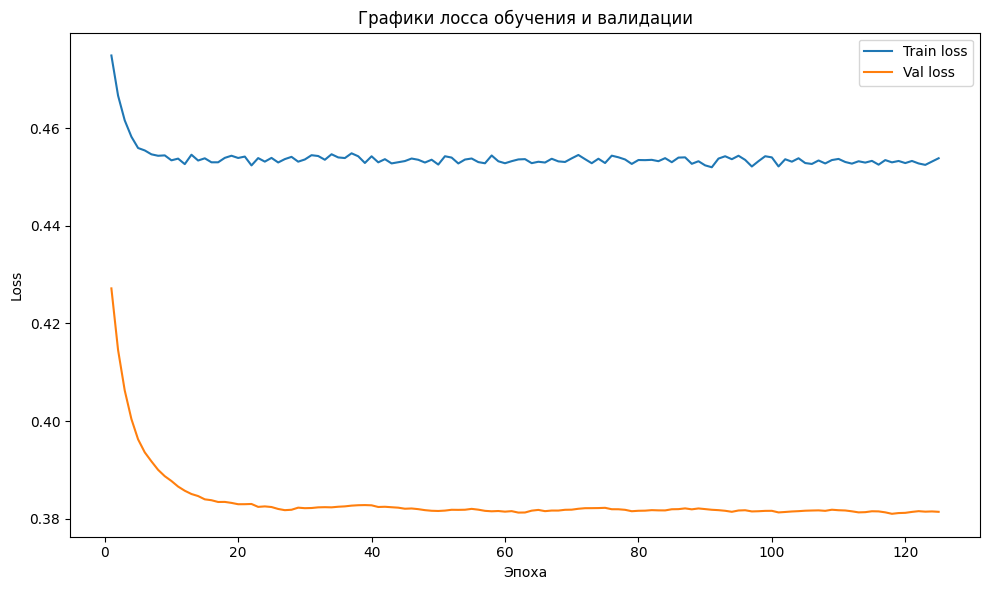

[I 2026-10-16 09:02:56,080] Trial 0 finished with value: 0.38343673620224 and parameters: {'n_layers': 9, 'activation': 'ReLU', 'dropout': 0.5146038780331599, 'n_units_l0': 71, 'n_units_l1': 94, 'n_units_l2': 96, 'n_units_l3': 103, 'n_units_l4': 95, 'n_units_l5': 86, 'n_units_l6': 87, 'n_units_l7': 117, 'n_units_l8': 98, 'num_epochs': 125, 'lr': 0.009978181466139392}. Best is trial 0 with value: 0.38343673620224.


Epoch [1/250], Loss: 0.4975
Val accuracy: 0.0%, loss = 0.5141234397888184
Epoch [2/250], Loss: 0.4980
Val accuracy: 0.0%, loss = 0.511531937122345
Epoch [3/250], Loss: 0.4958
Val accuracy: 0.0%, loss = 0.5090033888816834
Epoch [4/250], Loss: 0.4968
Val accuracy: 0.0%, loss = 0.5065266013145446
Epoch [5/250], Loss: 0.4941
Val accuracy: 0.0%, loss = 0.5041137933731079
Epoch [6/250], Loss: 0.4929
Val accuracy: 0.0%, loss = 0.5017863869667053
Epoch [7/250], Loss: 0.4917
Val accuracy: 0.0%, loss = 0.4995105743408203
Epoch [8/250], Loss: 0.4904
Val accuracy: 0.0%, loss = 0.49727495312690734
Epoch [9/250], Loss: 0.4898
Val accuracy: 0.0%, loss = 0.49512126445770266
Epoch [10/250], Loss: 0.4893
Val accuracy: 0.0%, loss = 0.4929980754852295
Epoch [11/250], Loss: 0.4876
Val accuracy: 50.0%, loss = 0.4909445881843567
Epoch [12/250], Loss: 0.4873
Val accuracy: 50.0%, loss = 0.4889049828052521
Epoch [13/250], Loss: 0.4850
Val accuracy: 50.0%, loss = 0.4869131088256836
Epoch [14/250], Loss: 0.4851
V

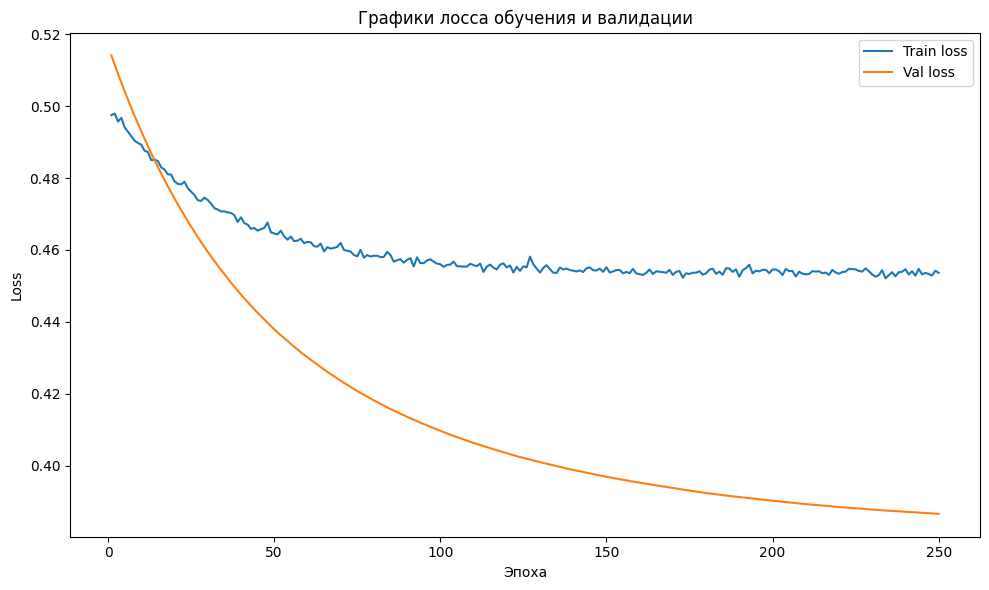

[I 2026-10-16 09:03:37,836] Trial 1 finished with value: 0.41490682082176206 and parameters: {'n_layers': 9, 'activation': 'ReLU', 'dropout': 0.4497590024829644, 'n_units_l0': 89, 'n_units_l1': 123, 'n_units_l2': 125, 'n_units_l3': 108, 'n_units_l4': 109, 'n_units_l5': 108, 'n_units_l6': 85, 'n_units_l7': 109, 'n_units_l8': 92, 'num_epochs': 250, 'lr': 0.0005902831248731999}. Best is trial 0 with value: 0.38343673620224.


Epoch [1/125], Loss: 0.5636
Val accuracy: 50.0%, loss = 0.44869235157966614
Epoch [2/125], Loss: 0.5478
Val accuracy: 50.0%, loss = 0.4079656362533569
Epoch [3/125], Loss: 0.5173
Val accuracy: 50.0%, loss = 0.3876302897930145
Epoch [4/125], Loss: 0.5196
Val accuracy: 50.0%, loss = 0.3859622418880463
Epoch [5/125], Loss: 0.5051
Val accuracy: 50.0%, loss = 0.3856110394001007
Epoch [6/125], Loss: 0.5010
Val accuracy: 50.0%, loss = 0.37973577380180357
Epoch [7/125], Loss: 0.4931
Val accuracy: 50.0%, loss = 0.381156861782074
Epoch [8/125], Loss: 0.4973
Val accuracy: 50.0%, loss = 0.3846899032592773
Epoch [9/125], Loss: 0.4902
Val accuracy: 50.0%, loss = 0.38638611435890197
Epoch [10/125], Loss: 0.4951
Val accuracy: 50.0%, loss = 0.3829332560300827
Epoch [11/125], Loss: 0.4883
Val accuracy: 50.0%, loss = 0.38310316801071165
Epoch [12/125], Loss: 0.4848
Val accuracy: 50.0%, loss = 0.3792355597019196
Epoch [13/125], Loss: 0.4785
Val accuracy: 50.0%, loss = 0.3758192539215088
Epoch [14/125], Lo

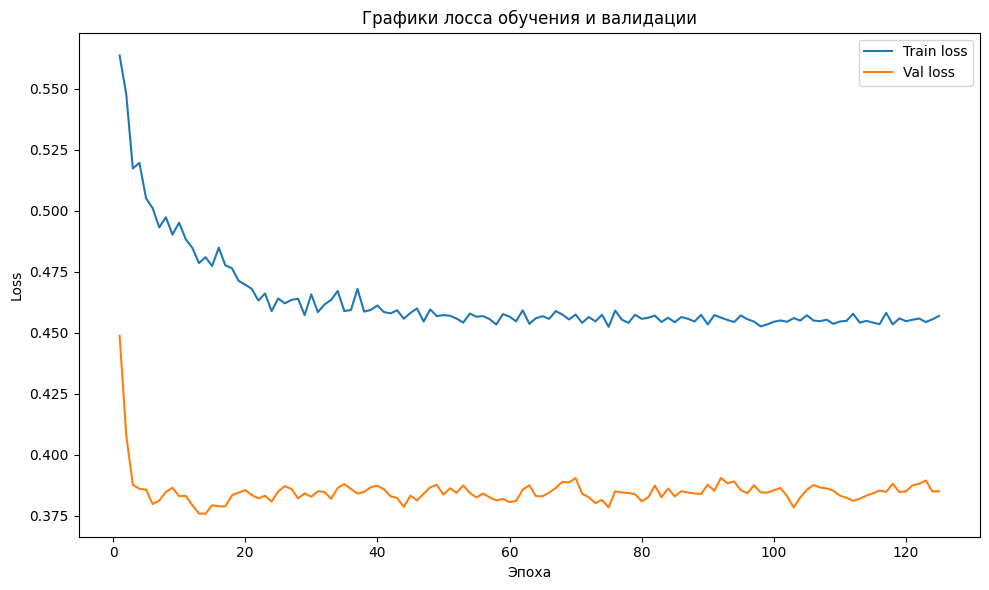

[I 2026-10-16 09:03:58,944] Trial 2 finished with value: 0.38485917408466336 and parameters: {'n_layers': 9, 'activation': 'Sigmoid', 'dropout': 0.7951030945363415, 'n_units_l0': 72, 'n_units_l1': 83, 'n_units_l2': 85, 'n_units_l3': 126, 'n_units_l4': 108, 'n_units_l5': 75, 'n_units_l6': 104, 'n_units_l7': 109, 'n_units_l8': 82, 'num_epochs': 125, 'lr': 0.0028441374050219175}. Best is trial 0 with value: 0.38343673620224.


Epoch [1/50], Loss: 0.4923
Val accuracy: 50.0%, loss = 0.49148560762405397
Epoch [2/50], Loss: 0.4757
Val accuracy: 50.0%, loss = 0.46362175345420836
Epoch [3/50], Loss: 0.4670
Val accuracy: 50.0%, loss = 0.44475293159484863
Epoch [4/50], Loss: 0.4621
Val accuracy: 50.0%, loss = 0.4310247302055359
Epoch [5/50], Loss: 0.4582
Val accuracy: 50.0%, loss = 0.42080104947090147
Epoch [6/50], Loss: 0.4570
Val accuracy: 50.0%, loss = 0.41305094957351685
Epoch [7/50], Loss: 0.4559
Val accuracy: 50.0%, loss = 0.4074393570423126
Epoch [8/50], Loss: 0.4545
Val accuracy: 50.0%, loss = 0.4028716742992401
Epoch [9/50], Loss: 0.4536
Val accuracy: 50.0%, loss = 0.3987633943557739
Epoch [10/50], Loss: 0.4544
Val accuracy: 50.0%, loss = 0.3954610288143158
Epoch [11/50], Loss: 0.4538
Val accuracy: 50.0%, loss = 0.3934402853250504
Epoch [12/50], Loss: 0.4530
Val accuracy: 50.0%, loss = 0.39130854308605195
Epoch [13/50], Loss: 0.4528
Val accuracy: 50.0%, loss = 0.38967111706733704
Epoch [14/50], Loss: 0.4529

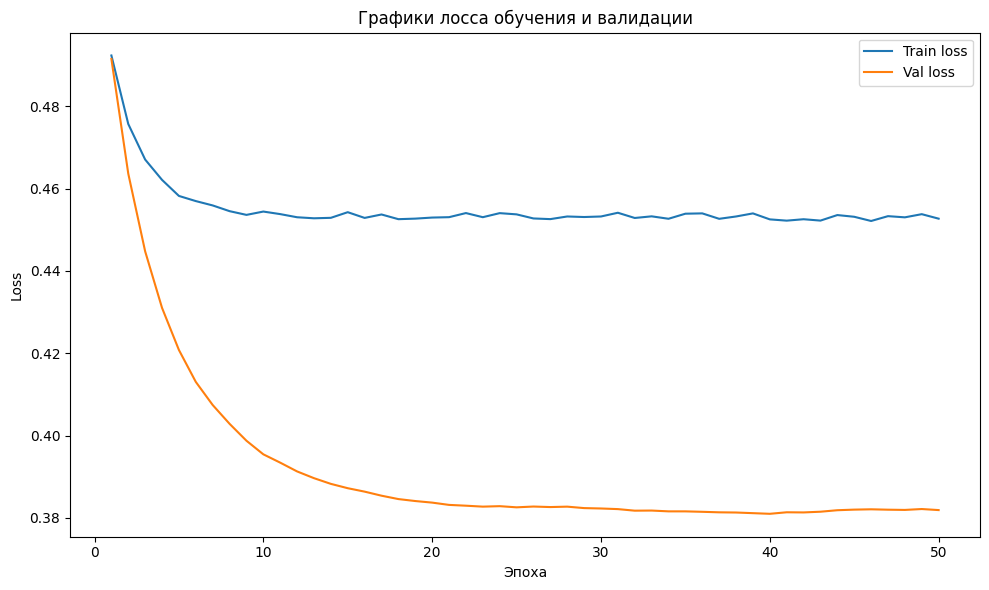

[I 2026-10-16 09:04:07,083] Trial 3 finished with value: 0.39208966636657716 and parameters: {'n_layers': 7, 'activation': 'ReLU', 'dropout': 0.2934344415381421, 'n_units_l0': 95, 'n_units_l1': 82, 'n_units_l2': 79, 'n_units_l3': 114, 'n_units_l4': 81, 'n_units_l5': 67, 'n_units_l6': 95, 'num_epochs': 50, 'lr': 0.009334646073387035}. Best is trial 0 with value: 0.38343673620224.


Epoch [1/200], Loss: 0.4724
Val accuracy: 50.0%, loss = 0.45242221355438234
Epoch [2/200], Loss: 0.4663
Val accuracy: 50.0%, loss = 0.4379071474075317
Epoch [3/200], Loss: 0.4585
Val accuracy: 50.0%, loss = 0.42469620108604433
Epoch [4/200], Loss: 0.4561
Val accuracy: 50.0%, loss = 0.41284623742103577
Epoch [5/200], Loss: 0.4452
Val accuracy: 50.0%, loss = 0.4007858633995056
Epoch [6/200], Loss: 0.4392
Val accuracy: 50.0%, loss = 0.3900580286979675
Epoch [7/200], Loss: 0.4361
Val accuracy: 50.0%, loss = 0.37917340695858004
Epoch [8/200], Loss: 0.4304
Val accuracy: 50.0%, loss = 0.36730281710624696
Epoch [9/200], Loss: 0.4228
Val accuracy: 50.0%, loss = 0.3550230711698532
Epoch [10/200], Loss: 0.4140
Val accuracy: 50.0%, loss = 0.34177292585372926
Epoch [11/200], Loss: 0.4066
Val accuracy: 50.0%, loss = 0.3280337661504745
Epoch [12/200], Loss: 0.4019
Val accuracy: 50.0%, loss = 0.31421355307102206
Epoch [13/200], Loss: 0.3885
Val accuracy: 50.0%, loss = 0.2985527977347374
Epoch [14/200]

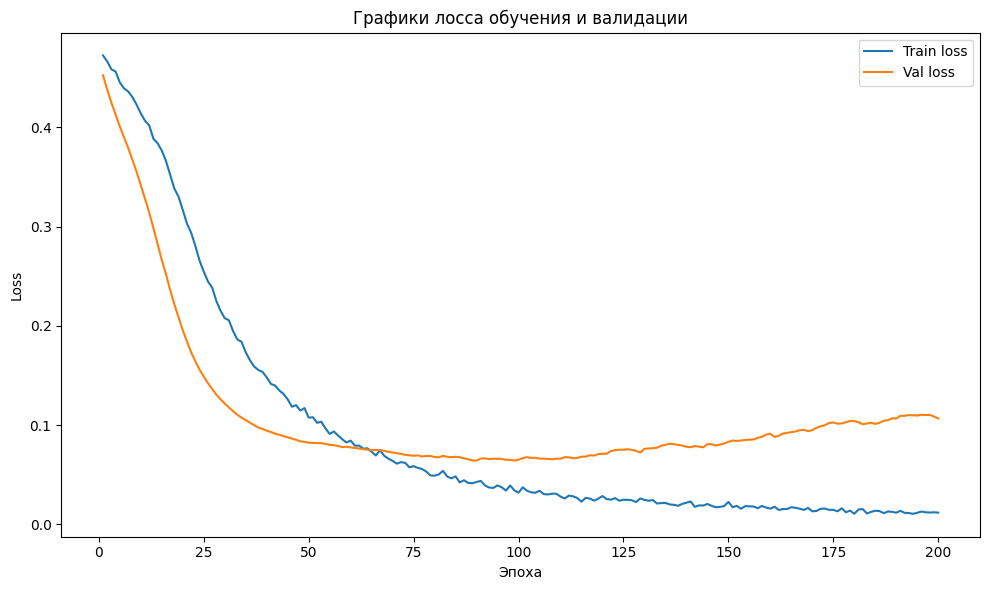

[I 2026-10-16 09:04:26,874] Trial 4 finished with value: 0.110753071470943 and parameters: {'n_layers': 3, 'activation': 'LeakyReLU', 'dropout': 0.5027499580176085, 'n_units_l0': 112, 'n_units_l1': 74, 'n_units_l2': 90, 'num_epochs': 200, 'lr': 0.004934354629347925}. Best is trial 4 with value: 0.110753071470943.


Epoch [1/225], Loss: 0.4866
Val accuracy: 50.0%, loss = 0.42395434379577634
Epoch [2/225], Loss: 0.4717
Val accuracy: 50.0%, loss = 0.40175589323043825
Epoch [3/225], Loss: 0.4734
Val accuracy: 50.0%, loss = 0.3915357828140259
Epoch [4/225], Loss: 0.4793
Val accuracy: 50.0%, loss = 0.3839039385318756
Epoch [5/225], Loss: 0.4727
Val accuracy: 50.0%, loss = 0.3838741362094879
Epoch [6/225], Loss: 0.4698
Val accuracy: 50.0%, loss = 0.381393101811409
Epoch [7/225], Loss: 0.4722
Val accuracy: 50.0%, loss = 0.38044935166835786
Epoch [8/225], Loss: 0.4727
Val accuracy: 50.0%, loss = 0.3787716269493103
Epoch [9/225], Loss: 0.4690
Val accuracy: 50.0%, loss = 0.380286505818367
Epoch [10/225], Loss: 0.4661
Val accuracy: 50.0%, loss = 0.3810713976621628
Epoch [11/225], Loss: 0.4611
Val accuracy: 50.0%, loss = 0.382541885972023
Epoch [12/225], Loss: 0.4688
Val accuracy: 50.0%, loss = 0.3816239655017853
Epoch [13/225], Loss: 0.4683
Val accuracy: 50.0%, loss = 0.3821911633014679
Epoch [14/225], Loss:

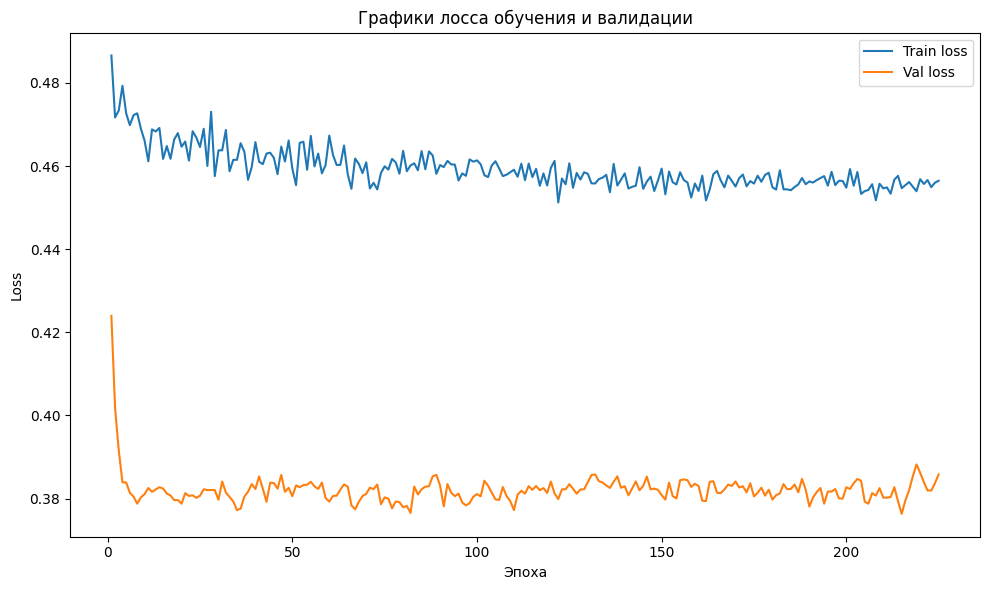

[I 2026-10-16 09:05:03,403] Trial 5 finished with value: 0.38209836513466305 and parameters: {'n_layers': 5, 'activation': 'Sigmoid', 'dropout': 0.3797293287227339, 'n_units_l0': 88, 'n_units_l1': 91, 'n_units_l2': 94, 'n_units_l3': 99, 'n_units_l4': 101, 'num_epochs': 225, 'lr': 0.0021728679063237207}. Best is trial 4 with value: 0.110753071470943.


Epoch [1/200], Loss: 0.4980
Val accuracy: 15.0%, loss = 0.5261335611343384
Epoch [2/200], Loss: 0.4670
Val accuracy: 28.125%, loss = 0.4850927829742432
Epoch [3/200], Loss: 0.4462
Val accuracy: 50.0%, loss = 0.45163167715072633
Epoch [4/200], Loss: 0.4247
Val accuracy: 50.0%, loss = 0.4230012059211731
Epoch [5/200], Loss: 0.4085
Val accuracy: 50.0%, loss = 0.39706791639328004
Epoch [6/200], Loss: 0.3883
Val accuracy: 50.0%, loss = 0.37418576776981355
Epoch [7/200], Loss: 0.3733
Val accuracy: 50.625%, loss = 0.35274098813533783
Epoch [8/200], Loss: 0.3589
Val accuracy: 51.25%, loss = 0.3329360067844391
Epoch [9/200], Loss: 0.3437
Val accuracy: 51.25%, loss = 0.31438302993774414
Epoch [10/200], Loss: 0.3231
Val accuracy: 53.125%, loss = 0.29551783949136734
Epoch [11/200], Loss: 0.3119
Val accuracy: 56.25%, loss = 0.27830114811658857
Epoch [12/200], Loss: 0.2974
Val accuracy: 60.0%, loss = 0.26283696889877317
Epoch [13/200], Loss: 0.2840
Val accuracy: 63.125%, loss = 0.24821823835372925
E

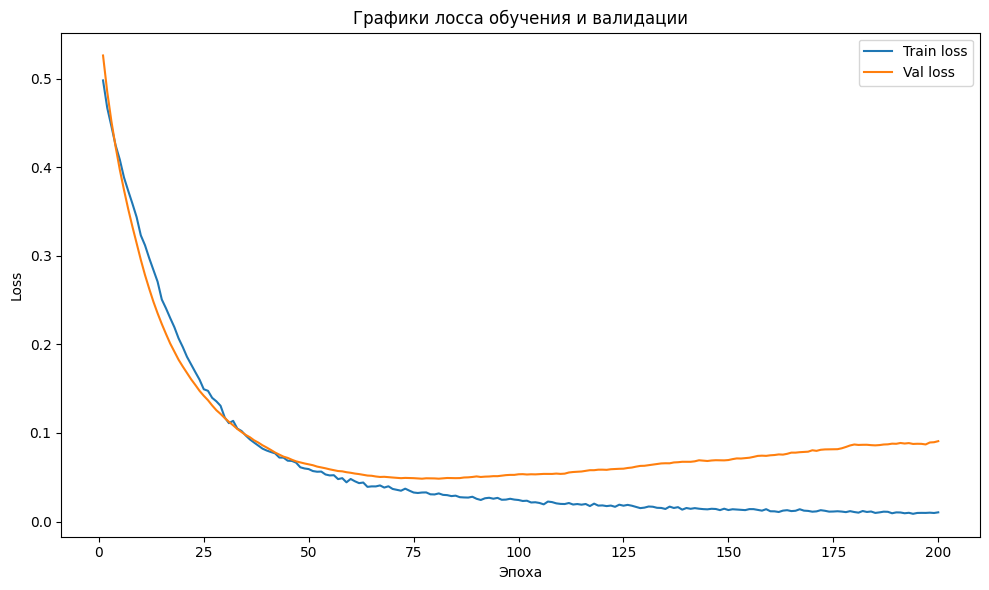

[I 2026-10-16 09:05:25,756] Trial 6 finished with value: 0.0949607991039474 and parameters: {'n_layers': 2, 'activation': 'ReLU', 'dropout': 0.30142375972927404, 'n_units_l0': 118, 'n_units_l1': 76, 'num_epochs': 200, 'lr': 0.0030540190859949306}. Best is trial 6 with value: 0.0949607991039474.


Epoch [1/75], Loss: 0.4643
Val accuracy: 86.875%, loss = 0.34139606952667234
Epoch [2/75], Loss: 0.3263
Val accuracy: 93.75%, loss = 0.23489894717931747
Epoch [3/75], Loss: 0.2498
Val accuracy: 96.25%, loss = 0.1792090080678463
Epoch [4/75], Loss: 0.2062
Val accuracy: 96.875%, loss = 0.14454446956515313
Epoch [5/75], Loss: 0.1725
Val accuracy: 96.875%, loss = 0.12053038850426674
Epoch [6/75], Loss: 0.1433
Val accuracy: 97.5%, loss = 0.10411258144304156
Epoch [7/75], Loss: 0.1223
Val accuracy: 97.5%, loss = 0.09294251636601984
Epoch [8/75], Loss: 0.1100
Val accuracy: 97.5%, loss = 0.08322304445318877
Epoch [9/75], Loss: 0.0956
Val accuracy: 97.5%, loss = 0.07580942690838129
Epoch [10/75], Loss: 0.0872
Val accuracy: 97.5%, loss = 0.07056296798400581
Epoch [11/75], Loss: 0.0769
Val accuracy: 97.5%, loss = 0.06583237022859975
Epoch [12/75], Loss: 0.0717
Val accuracy: 97.5%, loss = 0.06302716386271641
Epoch [13/75], Loss: 0.0668
Val accuracy: 97.5%, loss = 0.05986681086360477
Epoch [14/75],

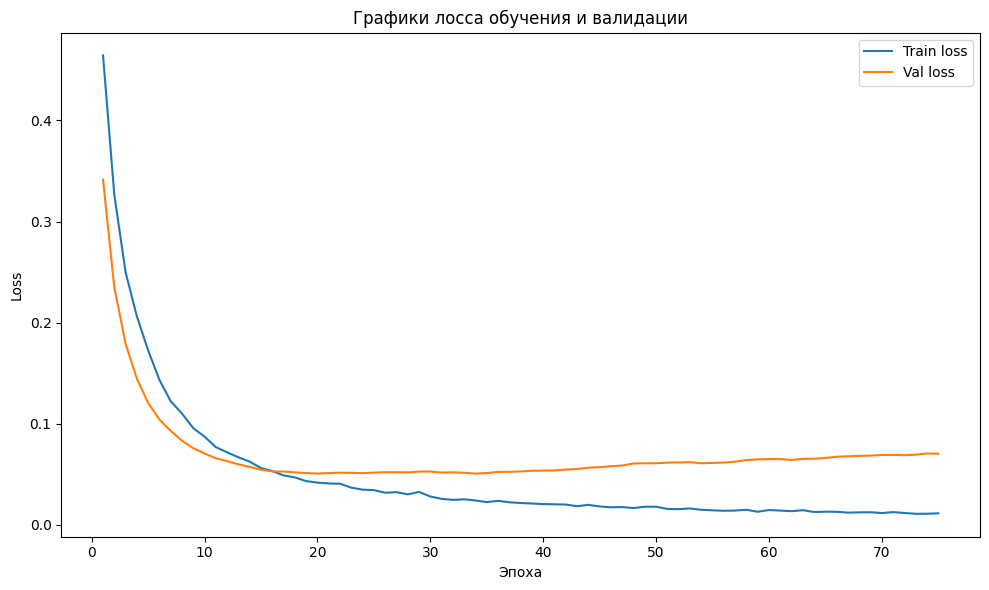

[I 2026-10-16 09:05:32,605] Trial 7 finished with value: 0.07021933451169601 and parameters: {'n_layers': 1, 'activation': 'ReLU', 'dropout': 0.3327070848535978, 'n_units_l0': 64, 'num_epochs': 75, 'lr': 0.0072287037585920455}. Best is trial 7 with value: 0.07021933451169601.


Epoch [1/125], Loss: 0.4885
Val accuracy: 50.0%, loss = 0.4704795002937317
Epoch [2/125], Loss: 0.4856
Val accuracy: 50.0%, loss = 0.46597354412078856
Epoch [3/125], Loss: 0.4842
Val accuracy: 50.0%, loss = 0.46174960732460024
Epoch [4/125], Loss: 0.4813
Val accuracy: 50.0%, loss = 0.45777963399887084
Epoch [5/125], Loss: 0.4788
Val accuracy: 48.125%, loss = 0.4540172219276428
Epoch [6/125], Loss: 0.4773
Val accuracy: 50.0%, loss = 0.4505172669887543
Epoch [7/125], Loss: 0.4753
Val accuracy: 50.0%, loss = 0.447201144695282
Epoch [8/125], Loss: 0.4742
Val accuracy: 50.0%, loss = 0.4441112160682678
Epoch [9/125], Loss: 0.4724
Val accuracy: 50.0%, loss = 0.44118441343307496
Epoch [10/125], Loss: 0.4722
Val accuracy: 50.0%, loss = 0.43847075700759885
Epoch [11/125], Loss: 0.4703
Val accuracy: 50.0%, loss = 0.4358512222766876
Epoch [12/125], Loss: 0.4688
Val accuracy: 50.0%, loss = 0.43337482213974
Epoch [13/125], Loss: 0.4685
Val accuracy: 50.0%, loss = 0.4310592234134674
Epoch [14/125], L

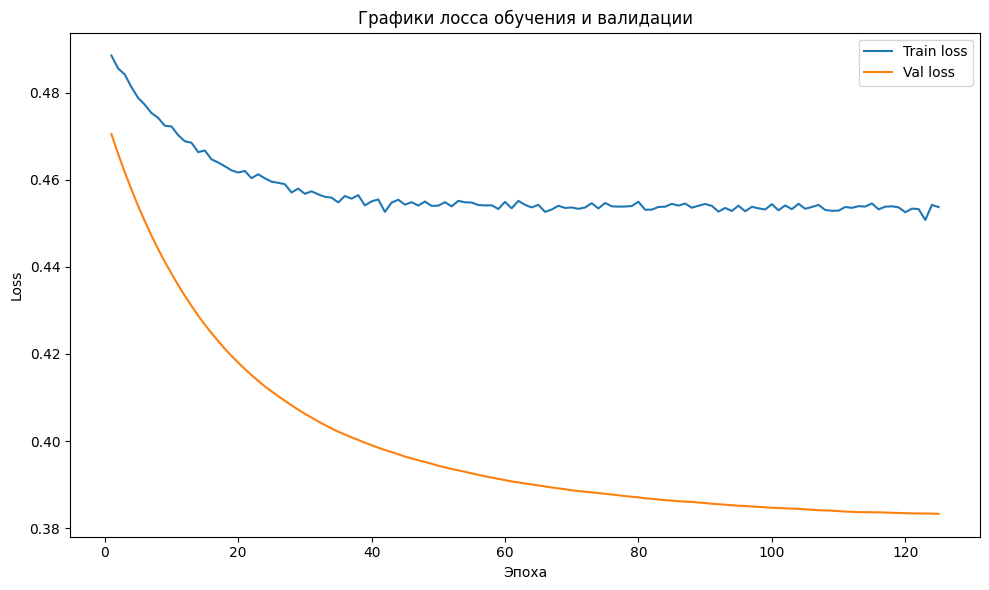

[I 2026-10-16 09:06:02,858] Trial 8 finished with value: 0.3991795532226562 and parameters: {'n_layers': 8, 'activation': 'LeakyReLU', 'dropout': 0.35074482317045785, 'n_units_l0': 117, 'n_units_l1': 94, 'n_units_l2': 70, 'n_units_l3': 113, 'n_units_l4': 74, 'n_units_l5': 111, 'n_units_l6': 95, 'n_units_l7': 71, 'num_epochs': 125, 'lr': 0.0014661048199000302}. Best is trial 7 with value: 0.07021933451169601.


Epoch [1/200], Loss: 0.4466
Val accuracy: 60.625%, loss = 0.3117919832468033
Epoch [2/200], Loss: 0.4058
Val accuracy: 55.625%, loss = 0.28956593573093414
Epoch [3/200], Loss: 0.3815
Val accuracy: 78.75%, loss = 0.24417921006679535
Epoch [4/200], Loss: 0.3503
Val accuracy: 78.125%, loss = 0.2331094890832901
Epoch [5/200], Loss: 0.3248
Val accuracy: 84.375%, loss = 0.21826135367155075
Epoch [6/200], Loss: 0.3020
Val accuracy: 88.125%, loss = 0.18754422068595886
Epoch [7/200], Loss: 0.2811
Val accuracy: 93.125%, loss = 0.16412573382258416
Epoch [8/200], Loss: 0.2635
Val accuracy: 95.625%, loss = 0.14897011928260326
Epoch [9/200], Loss: 0.2491
Val accuracy: 100.0%, loss = 0.13505491204559802
Epoch [10/200], Loss: 0.2332
Val accuracy: 100.0%, loss = 0.12571821585297585
Epoch [11/200], Loss: 0.2148
Val accuracy: 100.0%, loss = 0.10551112089306117
Epoch [12/200], Loss: 0.2010
Val accuracy: 100.0%, loss = 0.09877264238893986
Epoch [13/200], Loss: 0.1889
Val accuracy: 100.0%, loss = 0.09115350

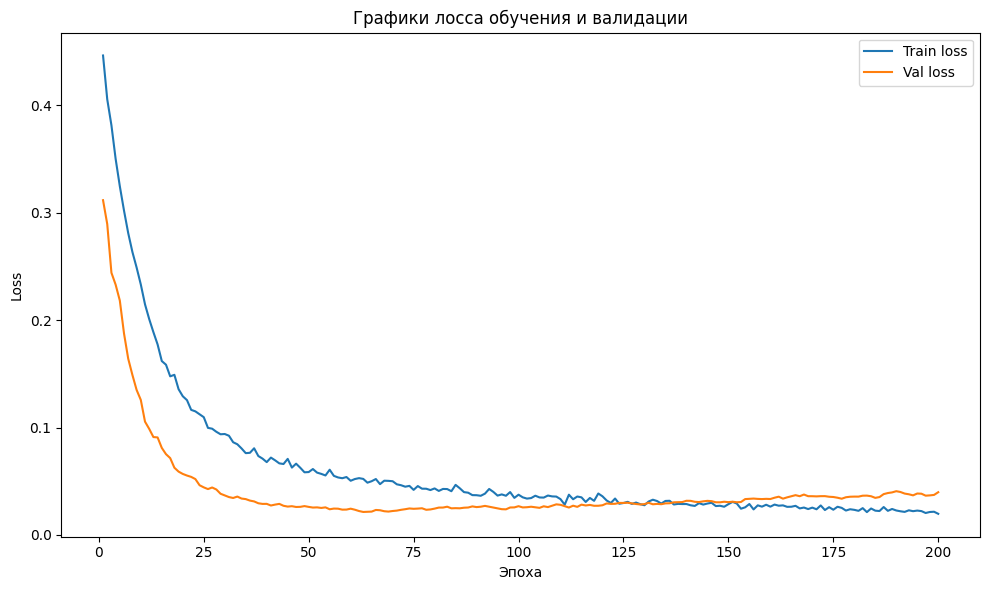

[I 2026-10-16 09:06:22,745] Trial 9 finished with value: 0.04173749045559397 and parameters: {'n_layers': 1, 'activation': 'Sigmoid', 'dropout': 0.288555363404711, 'n_units_l0': 83, 'num_epochs': 200, 'lr': 0.009334171200434139}. Best is trial 9 with value: 0.04173749045559397.


In [40]:
import optuna

objective, scaler = make_objective(train_test_idx)
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=10)

In [41]:
best_params = study.best_params
layers = []
in_features = X.shape[1]
activations = {"ReLU": nn.ReLU(), "Sigmoid": nn.Sigmoid(), "LeakyReLU": nn.LeakyReLU()}
for i in range(best_params["n_layers"]):
    out_features = best_params[f"n_units_l{i}"]
    layers.append(nn.Linear(in_features, out_features))
    layers.append(activations[best_params["activation"]])
    layers.append(nn.Dropout(best_params["dropout"]))
    in_features = out_features
layers.append(nn.Linear(in_features, N_CLASSES))

best_model = DeepFeedForward(layers)

In [42]:
def full_train(model, data_loader, criterion, optimizer, num_epochs):
    train_losses = []
    model.train()
    for i in range(num_epochs):
        running_loss = 0.0
        for inputs, labels in data_loader:
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        avg_loss = running_loss / len(data_loader)
        train_losses.append(avg_loss)
        print(f"Epoch [{i+1}/{num_epochs}], Loss: {avg_loss:.4f}")

    return model.state_dict()

In [43]:
X_normalized, _ = scale_features(X, scaler)
X_tensor = torch.tensor(X_normalized, dtype=torch.float32)
y_tensor = torch.tensor(y.to_numpy(), dtype=torch.long)
torch_dataset = TensorDataset(X_tensor, y_tensor)
full_train_loader = DataLoader(torch_dataset, batch_size=32, shuffle=False)

In [44]:
weights = calc_class_weights(np.asarray(y.to_numpy(), dtype=np.int64))
# criterion = nn.CrossEntropyLoss(weight=weights)
criterion = FocalLoss()
optimizer = torch.optim.Adam(best_model.parameters(), lr=best_params["lr"])

In [45]:
model_state = full_train(
    best_model,
    full_train_loader,
    criterion,
    optimizer,
    best_params["num_epochs"],
)

Epoch [1/200], Loss: 1.3099
Epoch [2/200], Loss: 1.4153
Epoch [3/200], Loss: 0.8718
Epoch [4/200], Loss: 0.4000
Epoch [5/200], Loss: 0.1358
Epoch [6/200], Loss: 0.1040
Epoch [7/200], Loss: 0.0986
Epoch [8/200], Loss: 0.0976
Epoch [9/200], Loss: 0.0905
Epoch [10/200], Loss: 0.0956
Epoch [11/200], Loss: 0.0915
Epoch [12/200], Loss: 0.0928
Epoch [13/200], Loss: 0.0847
Epoch [14/200], Loss: 0.0818
Epoch [15/200], Loss: 0.0825
Epoch [16/200], Loss: 0.0842
Epoch [17/200], Loss: 0.0793
Epoch [18/200], Loss: 0.0764
Epoch [19/200], Loss: 0.0757
Epoch [20/200], Loss: 0.0753
Epoch [21/200], Loss: 0.0718
Epoch [22/200], Loss: 0.0552
Epoch [23/200], Loss: 0.0533
Epoch [24/200], Loss: 0.0538
Epoch [25/200], Loss: 0.0387
Epoch [26/200], Loss: 0.0449
Epoch [27/200], Loss: 0.0371
Epoch [28/200], Loss: 0.0291
Epoch [29/200], Loss: 0.0313
Epoch [30/200], Loss: 0.0286
Epoch [31/200], Loss: 0.0386
Epoch [32/200], Loss: 0.0341
Epoch [33/200], Loss: 0.0248
Epoch [34/200], Loss: 0.0138
Epoch [35/200], Loss: 0

In [46]:
# save_path = Path.cwd() / "model"
# torch.save(model_state, save_path)

### Инференс


In [47]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


def evaluate_model(model, dataloader, device):
    model.eval()  # Set the model to evaluation mode
    all_preds = []
    all_labels = []

    with torch.no_grad():  # Disable gradient calculation
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    accuracy = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds, average="weighted")
    recall = recall_score(all_labels, all_preds, average="weighted")
    f1 = f1_score(all_labels, all_preds, average="weighted")

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "y_pred": all_preds,
        "y_true": all_labels,
    }

In [48]:
best_model.load_state_dict(model_state)

<All keys matched successfully>

In [49]:
all_mat_files = discover_mat_files(TEST_DIR)
test_catalog = build_catalog(all_mat_files, OUTPUT_ROOT)
test_catalog.to_parquet(OUTPUT_ROOT / "test_catalog.parquet", index=False)
test_catalog.to_csv(OUTPUT_ROOT / "test_catalog.csv", index=False)

  0%|          | 0/560 [00:00<?, ?it/s]

In [50]:
test_df = preprocessing(test_catalog)
X_true, y_true, _ = prepare_target(test_df)

0it [00:00, ?it/s]

In [51]:
X_true_normalized, _ = scale_features(X_true, scaler=scaler)

In [52]:
X_true_tensor = torch.tensor(X_true_normalized, dtype=torch.float32)
y_true_tensor = torch.tensor(y_true.to_numpy(), dtype=torch.long)

In [53]:
test_dataset = TensorDataset(X_true_tensor, y_true_tensor)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [54]:
metrics = evaluate_model(best_model, test_loader, "cpu")

Accuracy = 0.661
Macro F1 : 0.662

              precision    recall  f1-score   support

           0       0.99      0.93      0.95        80
           1       0.61      0.65      0.63       240
           2       0.61      0.58      0.59       240

    accuracy                           0.66       560
   macro avg       0.74      0.72      0.73       560
weighted avg       0.66      0.66      0.66       560



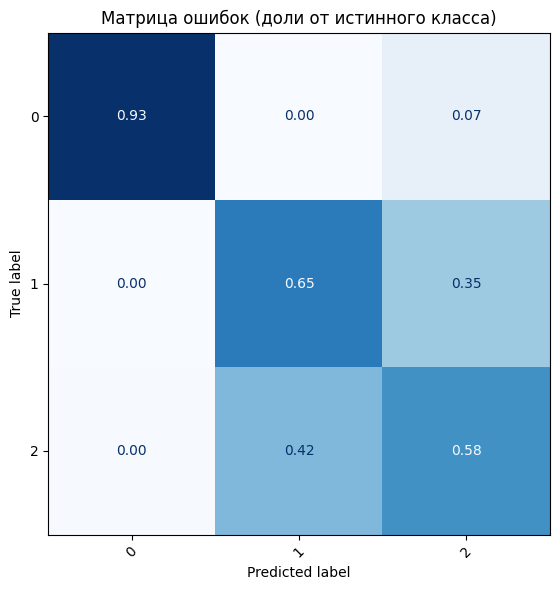

In [55]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
)
import matplotlib.pyplot as plt

print(f"Accuracy = {metrics["accuracy"]:.3f}")
print(f"Macro F1 : {metrics["f1_score"]:.3f}\n")
print(classification_report(metrics["y_true"], metrics["y_pred"], zero_division=0))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    metrics["y_true"],
    metrics["y_pred"],
    normalize="true",
    values_format=".2f",
    xticks_rotation=45,
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
ax.set_title("Матрица ошибок (доли от истинного класса)")
plt.tight_layout()
plt.show()